# NAVTTC Week 6 - Task 55
## Time Series Analysis with Pandas

## Objective
Demonstrate common **time-series analysis** operations using Pandas: datetime indexing, resampling, rolling statistics, lag features, differencing, and autocorrelation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
dates = pd.date_range("2026-01-01", periods=180, freq="D")
trend = np.linspace(50, 80, len(dates))
seasonal = 8 * np.sin(np.arange(len(dates)) * 2 * np.pi / 30)
noise = rng.normal(0, 2, len(dates))

ts = pd.Series(trend + seasonal + noise, index=dates, name="Value")
print(ts.head())

2026-01-01    50.609434
2026-01-02    49.750923
2026-01-03    55.089991
2026-01-04    57.086205
2026-01-05    52.713479
Freq: D, Name: Value, dtype: float64


## Plot the Time Series

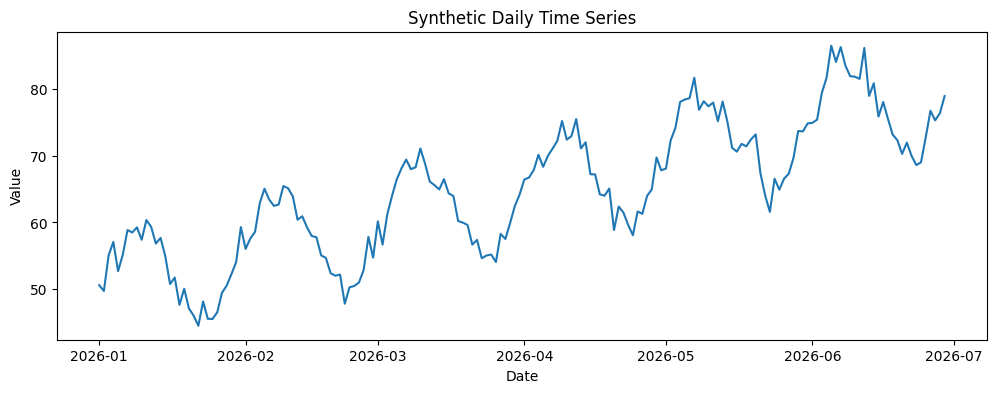

In [2]:
plt.figure(figsize=(12, 4))
plt.plot(ts.index, ts.values)
plt.title("Synthetic Daily Time Series")
plt.xlabel("Date")
plt.ylabel("Value")
plt.show()

## Resampling
Resampling changes the time frequency. Here daily values are summarized into weekly means.

In [3]:
weekly_mean = ts.resample("W").mean()
print(weekly_mean.head())

2026-01-04    53.134138
2026-01-11    57.468426
2026-01-18    54.150046
2026-01-25    46.733829
2026-02-01    52.609777
Freq: W-SUN, Name: Value, dtype: float64


## Rolling Statistics

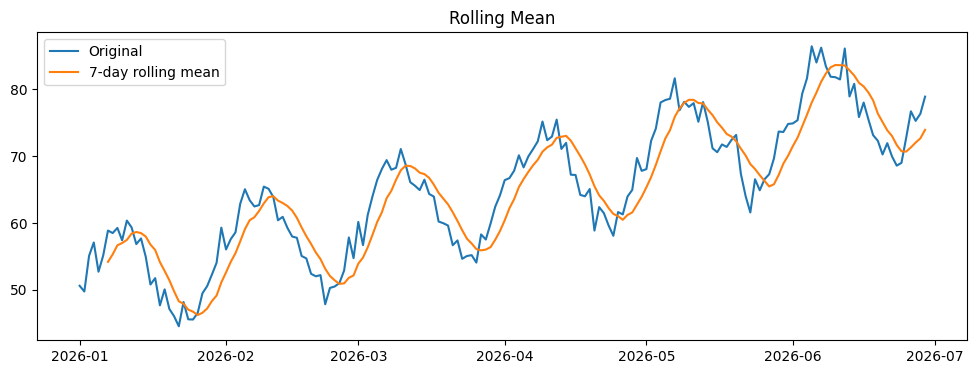

In [4]:
rolling_mean = ts.rolling(window=7).mean()
rolling_std = ts.rolling(window=7).std()

plt.figure(figsize=(12, 4))
plt.plot(ts.index, ts.values, label="Original")
plt.plot(rolling_mean.index, rolling_mean.values, label="7-day rolling mean")
plt.legend()
plt.title("Rolling Mean")
plt.show()

## Lag Features and Differencing

In [5]:
df = ts.to_frame()
df["Lag_1"] = df["Value"].shift(1)
df["Lag_7"] = df["Value"].shift(7)
df["First_Difference"] = df["Value"].diff()
print(df.head(10))

                Value      Lag_1      Lag_7  First_Difference
2026-01-01  50.609434        NaN        NaN               NaN
2026-01-02  49.750923  50.609434        NaN         -0.858511
2026-01-03  55.089991  49.750923        NaN          5.339068
2026-01-04  57.086205  55.089991        NaN          1.996214
2026-01-05  52.713479  57.086205        NaN         -4.372725
2026-01-06  55.161833  52.713479        NaN          2.448354
2026-01-07  58.869720  55.161833        NaN          3.707886
2026-01-08  58.496874  58.869720  50.609434         -0.372845
2026-01-09  59.263355  58.496874  49.750923          0.766481
2026-01-10  57.410744  59.263355  55.089991         -1.852611


## Autocorrelation

In [6]:
for lag in [1, 7, 30]:
    print(f"Lag {lag} autocorrelation:", round(ts.autocorr(lag=lag), 4))

Lag 1 autocorrelation: 0.9652
Lag 7 autocorrelation: 0.6798
Lag 30 autocorrelation: 0.9558


## Conclusion
This task demonstrates standard Pandas time-series operations. Synthetic data are used because the PDF does not provide a mandatory dataset.